# When exploration follows the wrong signal

**Does an algorithm solve the easy case, then deteriorate when irrelevant opportunities or misleading cues increase?** Each main panel follows **one algorithm over time**. Increasing darkness means increasing pathology; upward-fanning cumulative-regret curves expose the additional learning cost. Bands are one sample standard deviation across three held-out seeds, truncated at zero for regret; they are not confidence intervals. All panels within a figure use the same linear scale.

This adopts the visual logic of the variable-sparsity panel in [STEERING](https://arxiv.org/abs/2301.12038) (Figure 2(c) in arXiv v2; the earlier discussion referred to Figure 1(c)). Here the intervention is an explicit environmental change, rather than a sparsity label.

The evidence is 144 physical-burden cells and 90 prior-shift cells. These are **two-step junction variants**, not the historical full DeepSea/Frozen Lake grids. Every dose is a separate stationary run; there is no within-run change point. The original rho sweep did not establish this easy-to-hard transition.

**Fresh optimizer confirmation:** the separate stability section adds five new seeds and reveals additional original-CEAC actor failures at maximum Undertow burden. A guarded natural update reduces these errors while preserving both critics and evidence-priced replay. The earlier comparison figures below retain their original optimizer and three-seed slate.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ceac_hardness').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from ceac_hardness.report import load_export, draw_junctions
from ceac_walkthrough.mechanisms import load_mechanisms
from ceac_walkthrough.failure_report import draw_failure_fans, draw_critic_mechanism
burden = load_export(ROOT / 'notebooks/evidence/hardness_burden')
prior = load_export(ROOT / 'notebooks/evidence/hardness_prior')
audit = load_mechanisms(ROOT / 'notebooks/evidence/mechanisms')
print(f"Verified {len(burden['runs'])} burden cells, {len(prior['runs'])} prior cells, and {len(audit['cells'])} saved-update audits. No training launched.")

Verified 144 burden cells, 90 prior cells, and 54 saved-update audits. No training launched.


## 1. More exploration opportunities, no more task information

**Undertow** adds B zero-reward dead-end actions. **False Beacon** offers one action reaching a uniformly chosen cell in a zero-reward chamber of breadth B. Safe, risky and diagnostic actions keep exactly the same rewards and information. Every episode still takes two physical interactions. B = 0, 4, 16, 64; the two variants share the same B=0 kernel.

Independent calibration checked both tasks on seeds 1001/1002, requiring final gap ≤ 0.025. The held-out burden study uses task 1 (risky route optimal), seeds 0/1/2 and 262,144 interactions for every method. Domain growth changes both occupancy entropy and the published optimism bonuses; this is the intended intervention.

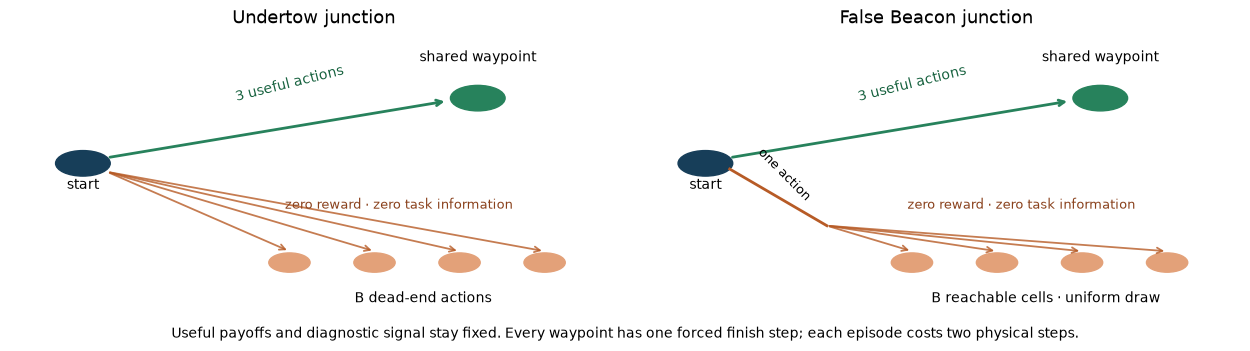

In [2]:
fig = draw_junctions()
plt.show()

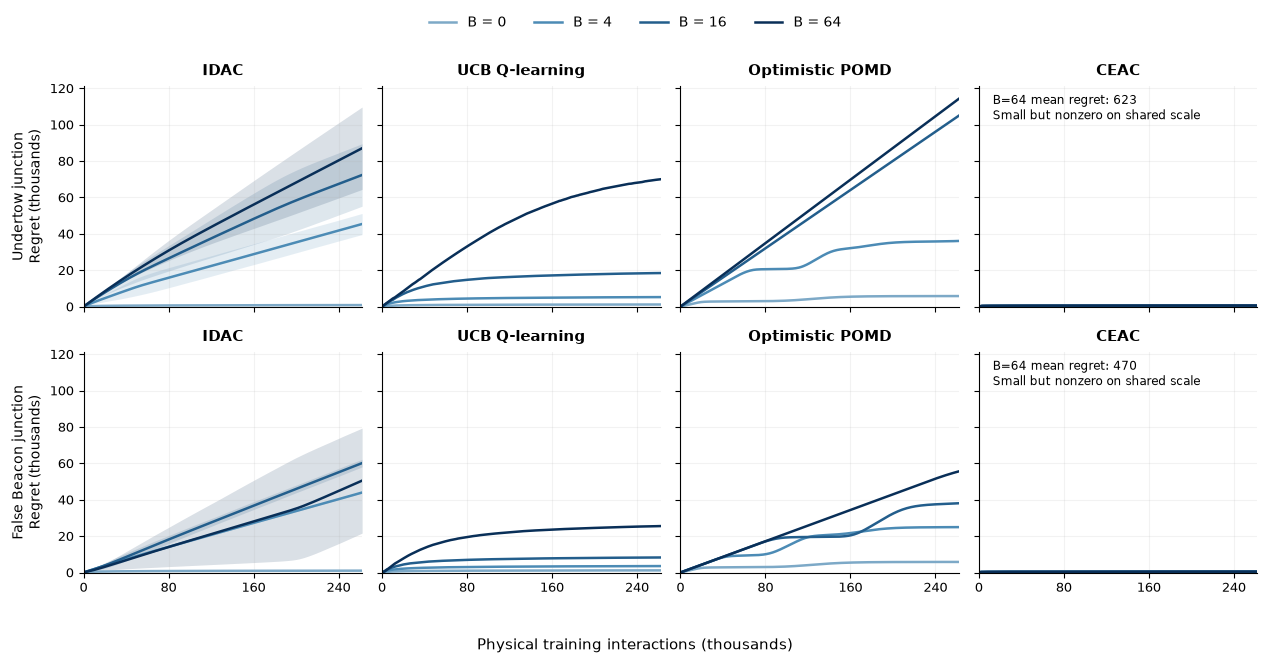

In [3]:
fig = draw_failure_fans(burden)
plt.show()

### Read the failures by mechanism

**Coverage / IDAC:** broad occupancy rewards irrelevant states. For nuisance probability p, with the remaining mass on the optimal useful action, the exact population objective is C(p)/(H(p)+0.1), where C(p)=1.01−0.45(1−p) and H(p)=log(2)+[h(p)+p log B]/2. Its preferred nuisance mass grows with breadth. This is a population-objective diagnosis; the implemented 16-episode occupancy estimator need not reach that optimum. False Beacon IDAC is worse at B=16 than B=64 in mean cumulative regret: breadth exposes a failure relative to B=0, but does not strictly order every finite-budget result.

**Greedy UCB Q-learning:** extra state/action uncertainty incurs a large finite-budget learning cost. A steep early curve is different from permanent failure: some hard seeds recover near the end.

**Optimistic softmax POMD:** at Undertow B=64 all optimistic cost-Q values remain clipped to zero for the entire run. Equal optimistic costs leave the policy uniform across 67 actions. The resulting exact policy gap is 0.9−(0.5+0.9+0.48)/67 = **0.87194**, matching the measured endpoint. This explains the nearly linear hard-case regret.

**CEAC:** the nuisance observations have zero likelihood-ratio evidence for every task pair. Increasing their number does not create evidence credit. The learned policy avoids this large exploration cost, with small nonzero regret on the shared scale.

| Variant | Mechanism | Final policy loss, B=0 → 64 | Regret at B=64 | Irrelevant episodes at B=64 |
|---|---|---:|---:|---:|
| Undertow | IDAC: occupancy | 0.00128 → 0.60244 | 87,060 | 72.0% |
| Undertow | UCB: uncertainty | 0.00000 → 0.07768 | 70,008 | 58.3% |
| Undertow | POMD: optimism | 0.00058 → 0.87194 | 114,287 | 95.5% |
| Undertow | CEAC: evidence | 0.00001 → 0.00001 | 623 | 0.2% |
| False Beacon | IDAC: occupancy | 0.00132 → 0.51522 | 50,496 | 41.2% |
| False Beacon | UCB: uncertainty | 0.00000 → 0.01216 | 25,516 | 20.5% |
| False Beacon | POMD: optimism | 0.00060 → 0.30783 | 55,604 | 24.1% |
| False Beacon | CEAC: evidence | 0.00001 → 0.00002 | 470 | 0.0% |

Final loss averages the last 256 episodes; regret counts the entire learning period. **Product-support IDS and the offline Graves–Lai oracle also succeed:** their mean final loss is zero throughout this burden sweep; mean cumulative regret is at most 0.694 for product-support IDS and zero for the oracle. Their complete learning panels are retained in the supporting report. CEAC is not the only successful model-informed method.

[All six algorithms, every dose and seed](evidence/hardness_burden/assessment.md).

## 2. Bayesian information can point toward the wrong task

A mandatory cue precedes a safe/risky/probe decision. Freeze the correlated prior at two equally weighted joint models: **(task 0, q=0.1)** and **(task 1, q=0.9)**. Both task labels and every possible observation retain positive probability.

For true task 1, increase reversal d by setting q(d)=0.9−0.8d; task 0 uses q(d)=0.1+0.8d. Every nonzero registered d excludes the true *joint law* from this prior. Under task 1 the cue alone adds expected log odds (2q−1)log(9) for task 1; this sign reverses after d=0.5. More data can then strengthen the wrong belief.

Product-support IDS and CEAC use the same ten-model Cartesian class (two tasks × five cue probabilities). For every cue law it includes an opposite-task alternative with **the same q**, which the cue alone cannot distinguish. All three methods receive 65,536 physical interactions per run. Both tasks stay visible below.

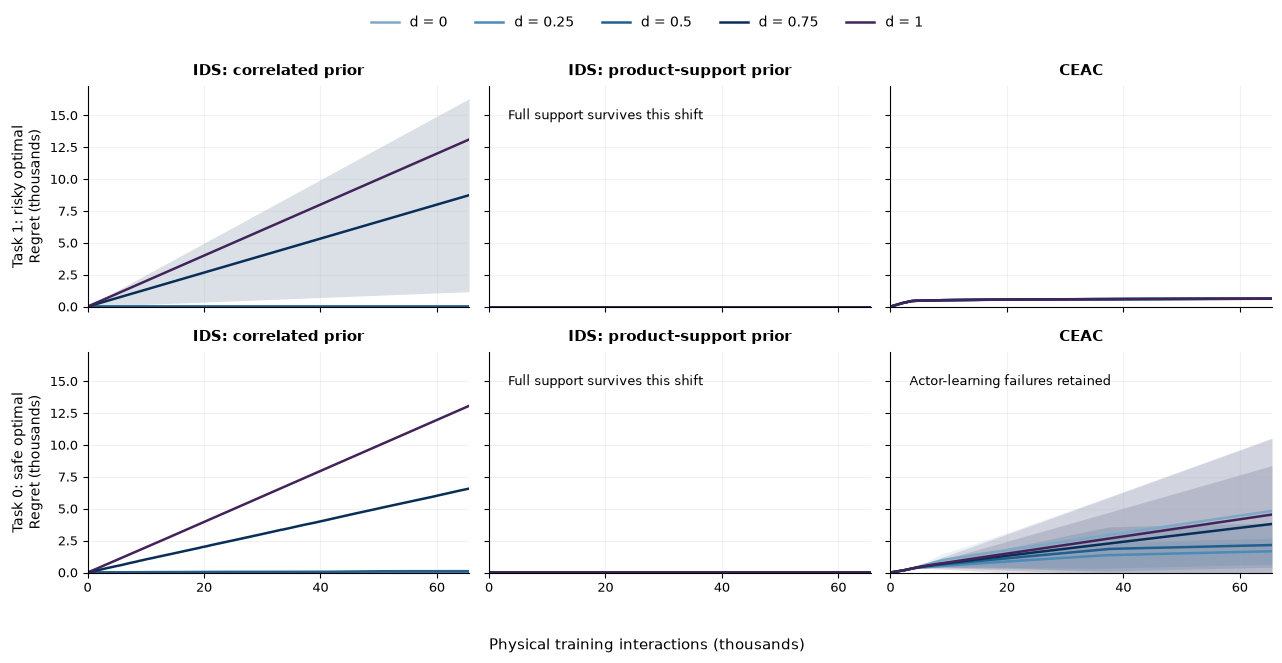

In [4]:
fig = draw_failure_fans(prior)
plt.show()

At full reversal, correlated IDS has mean final loss **0.4 on both tasks**; product-support IDS remains near zero. This demonstrates failure of the restrictive task–cue prior, not an intrinsic failure of Bayesian IDS. Leaving support at d>0 is not itself a monotone guarantee of failure: the conspicuous behavioral break appears at stronger reversal.

On task 1, CEAC's final loss remains approximately **0.0048** across doses. **Task 0 is an exception:** seed 0 has large loss at d=0, 0.75 and 1; other seeds retain roughly 0.023 loss. These runs remain in the means and bands. Increasing dose is a controlled misspecification intervention, not a universal hardness ranking for every algorithm and task.

[All endpoints and wrong-task posterior diagnostics](evidence/hardness_prior/assessment.md).

## 3. Where the evidence critic enters the actual CEAC update

CEAC here is the manuscript's **reward critic + price-conditioned evidence critic + evidence-priced, policy-labeled replay**, in one episode loop. Its actor uses the sum of the two frozen TD errors; the critics then update from those same errors. Statistical and design debts select diagnostic episodes before the actor is allowed to act. There is no exact-model deployment branch.

The hard Undertow example below separates three questions: which observations distinguish tasks, how reward/evidence TD terms moved the logits, and how the actor's probabilities changed. The first panel is an exact kernel calculation; the other panels reconstruct saved actor updates and average all three hard-case seeds. The probability panel zooms to the first 12,000 interactions and shows the current actor, not the diagnostic policies executed before it.

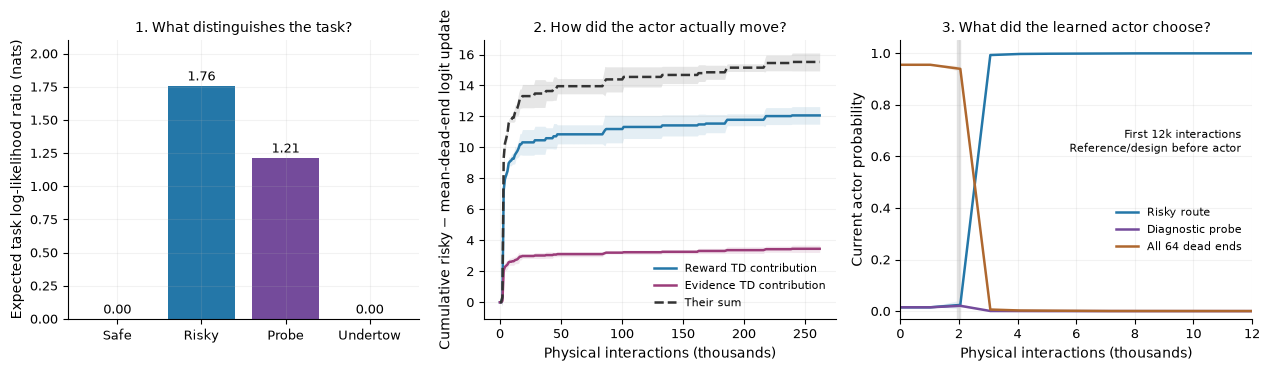

In [5]:
fig = draw_critic_mechanism(audit)
plt.show()

**Measured contribution:** at Undertow B=64, the cumulative risky-minus-mean-dead-end logit increment decomposes into **12.07 from reward TD** and **3.45 from evidence TD**, averaged over seeds. Their sum is the actual actor increment. At False Beacon B=64 the analogous evidence increment is **2.84**. Here reward and task discrimination favor the same risky route. Positive evidence contribution reinforces that route; it is not a measured counterfactual improvement in final return.

**Timing matters:** the first certified replay design precedes or coincides with the first actor episode (episode 972 in these hard runs, zero-based). Thus initial reference identification is achieved by statistical replay before the learned evidence critic updates. The performance curves support the combined CEAC mechanism; they do not establish that the critic caused that initial identification.

**Replay really uses evidence prices:** for every logged design we verify `priced score = empirical return + beta × empirical likelihood-ratio evidence`. The audit reconstructs all **3,795,360 actor/two-critic updates across 54 CEAC runs**, checks every recorded actor-policy identity, and checks that reward/evidence increments sum to the actual update (maximum per-step residual 9.2e-16). This uses saved observations, with no new training or alternative policy trajectory.

For the prior-shift family, an opposite-task model with the same q always gives zero cue evidence. Finite-radius design prices can still credit the cue against a different-q alternative; it would be incorrect to claim that CEAC gives every cue zero price. Same-q task-changing constraints still require decision-relevant observations.

## 4. When evidence is insufficient

**Correct model identification does not guarantee a well-optimized actor.** The saved task-0/d=0 failure has the correct reference and finite critic values. Its evidence contribution toward risky exceeds the opposing reward contribution; a substantial augmented-objective optimization residual remains. The same settings on all three seeds give the following exact cumulative risky-minus-safe logit decomposition (weighted by true cue-state visitation):

| Task 0, d=0 | Reward contribution | Evidence contribution | Final policy loss |
|---|---:|---:|---:|
| Seed 0 | -7.28 | +15.22 | 0.3581 |
| Seed 1 | -3.46 | +4.11 | 0.0229 |
| Seed 2 | -20.11 | +22.36 | 0.0230 |

These signed contributions explain recorded movement; they do not establish the outcome of removing or retuning the critic. The implementation has not been tuned on these held-out failures. An evidence critic can help direct learning toward informative behavior and still leave finite-budget optimization or over-exploration problems.

**Scope of the comparison:** IDAC/UCB/POMD receive primitive trajectories and public state/action masks; CEAC and IDS additionally receive candidate likelihoods and model-based responses. The offline Graves–Lai oracle additionally knows the realized model and fixes its design from that truth. This is a comparison of exploration mechanisms under explicit information assumptions, not a matched model-free architecture comparison. Three seeds provide descriptive evidence, not a population-level guarantee.

## Actor stability: learning cost and final optimization error

All settings keep the reward critic, evidence critic and evidence-priced replay. The frozen 56-cell calibration selected the **original constant-rate update** because it minimized worst-cell final priced-objective error. The guarded natural update (initial step 0.03) also passed both gates and reduced mean calibration regret by about 49%.

Before inspecting confirmation outcomes, a separate secondary comparison was registered for every non-reference calibration passer. Only the guarded natural 0.03 setting qualified. It is an explicit optimizer extension; it does not replace the primary CEAC definition or its existing comparator results.

**Largest registered Undertow burden (B=64), task 0:** mean regret changes from 22,550 to 3,467 (84.6% lower). The worst actor priced-objective gap changes from 0.2471 to 0.0020. The original update can still fail at the longer budget; the natural update avoids those large optimization residuals in these five seeds.

**Fresh-seed cue result:** the worst task-0 actor priced-objective gap changes from 0.1542 to 0.0025. Using the calibration gap threshold (0.005) descriptively, 4/25 original cue cells and 0/25 natural cells exceed it. Lower cue regret occurs on 1/5 seed-averaged task-0 sequences: the mean benefit is driven by avoiding a costly failure, not consistently faster learning. The largest task-0 late reward gap changes from 0.3952 to 0.0270. Task 1 shows the cost of stabilization: mean late reward gap changes from 0.00485 to 0.00628; 98.5% of the natural update's mean final priced-objective gap is the cost of its imposed floor. This supports fewer large actor failures in the measured cue conditions, not universal improvement. Five seeds and their full paired dispersion are retained below.

Fresh-seed learning costs below average all registered doses within each family/task. Differences are **natural minus original**, with sample SD across the five seed-paired, dose-averaged differences. Negative is better; these are descriptive differences, not significance claims.

| Family | Task | Original regret | Natural regret | Paired difference ± SD |
|---|---:|---:|---:|---:|
| False Beacon | 0 | 4,438 | 2,979 | -1,460 ± 3,551 |
| False Beacon | 1 | 473 | 686 | 213 ± 10 |
| Undertow | 0 | 8,395 | 3,162 | -5,233 ± 6,449 |
| Undertow | 1 | 722 | 895 | 174 ± 359 |
| Cue reversal | 0 | 2,224 | 1,523 | -702 ± 2,060 |
| Cue reversal | 1 | 618 | 712 | 94 ± 1 |

The figure shows the registered easy cue case (d=0) and maximum Undertow burden (B=64), both tasks and all five seeds. Panels use their own scales and registered episode budgets; all intermediate doses remain in the supporting plots. Full dose responses, terminal reward gaps, floor-constrained optimization gaps and raw per-seed differences are retained in the [stability assessment](evidence/actor_stability/assessment.md). A remaining task-0 reward loss near 0.02 can reflect priced probing (probe reward 0.48 versus safe reward 0.50), even when actor optimization is accurate. Temporary zero prices during replay recertification can produce objective-gap spikes while the actor is frozen; the evaluated objective has changed. These new seeds compare complete CEAC optimizer settings; the external algorithms in the earlier figures used a different seed set.

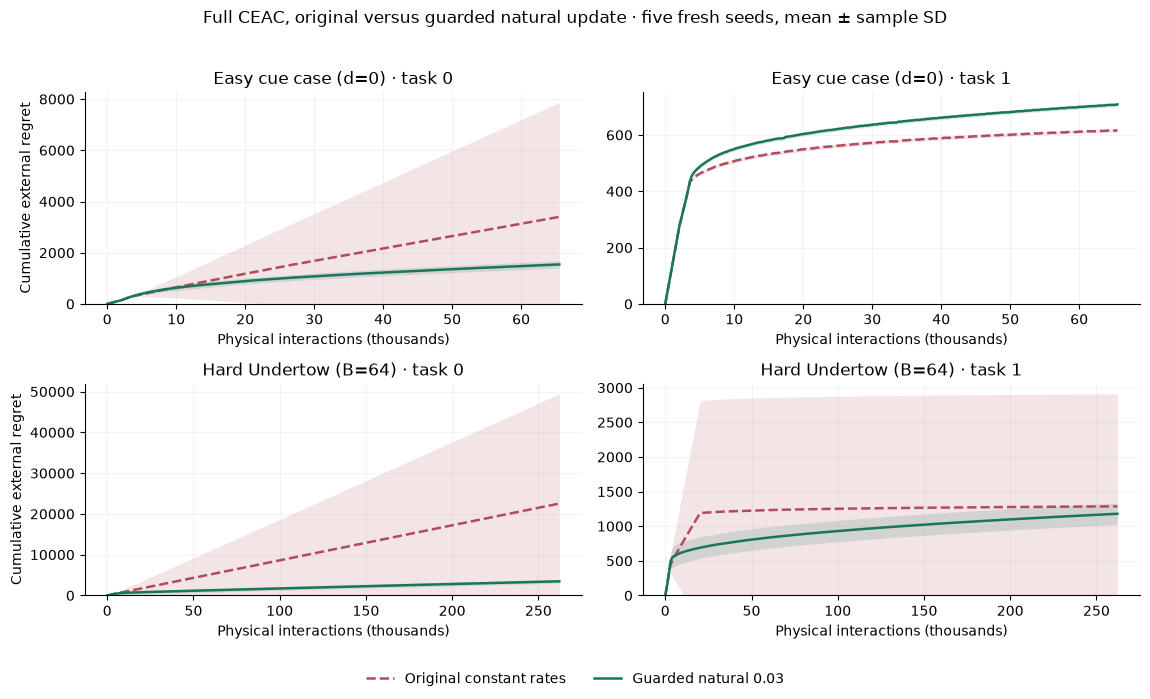

In [6]:
from ceac_stability.report import load_export as load_stability, combined_confirmation, draw_confirmation_learning
stability = load_stability(ROOT / 'notebooks/evidence/actor_stability')
fig = draw_confirmation_learning(combined_confirmation(stability))
plt.show()

## Evidence and reproduction

The [curated report](evidence/mechanisms/report.md) and [PDF](evidence/mechanisms/report.pdf) follow this same narrative. [Supporting mechanism checks](evidence/mechanisms/objective_diagnostics.png) show the population IDAC objective, measured POMD saturation and the correlated prior's cue evidence.

The [implementation guide](../docs/hardness_implementation.md), [comparator source ledger](../docs/comparator_provenance.md) and [equation-level CEAC audit](../audits/ceac_pseudocode_fidelity_20261111.md) specify the algorithms. The [historical diagnostic notebook](Undertow_FalseBeacon_Diagnostics.ipynb) retains the earlier grid studies; its exact-deployment reference is not primary CEAC.

The report is rebuilt by `scripts/render_hardness.py`. The notebook reads only compact, hash-verified exports; it never needs raw trajectories or launches training. `scripts/export_critic_updates.py` can rebuild the update audit from the immutable saved episodes and design histories.